# Prueba de integración · CoinGecko API ↔ Financial-Toolkit

Este notebook comprueba la API Key, los imports, los endpoints de CoinGecko y la construcción de `Cryptocurrency`, `Tokenomics` y `PriceSeries`.

**Ubicación recomendada:** `Financial-Toolkit/tests/test_coingecko_financial_toolkit.ipynb`. Abre el proyecto en VS Code y ejecuta las celdas en orden. También funciona si el kernel comienza en la raíz del repositorio. Requiere conexión a internet y una API Key Demo válida; nunca se imprime la clave.


In [1]:
# Si faltan dependencias, ejecuta una vez:
# %pip install requests pandas python-dotenv matplotlib

from pathlib import Path
import os, sys, importlib, traceback
import pandas as pd
import requests
from dotenv import load_dotenv

# Jupyter puede ejecutar el kernel desde tests/ o desde la raíz del repositorio.
# Subimos por los directorios hasta encontrar pyproject.toml y src/models.
def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "src" / "models").is_dir() and (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError(
        "No se encuentra Financial-Toolkit. Ejecuta Jupyter desde tests/ "
        "o desde la raíz del proyecto (debe contener pyproject.toml y src/models)."
    )

ROOT = find_project_root(Path.cwd().resolve())
for path in (ROOT, ROOT / "src", ROOT / "src" / "models"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

load_dotenv(ROOT / ".env")
print("Raíz del proyecto:", ROOT)
print("Archivo .env encontrado:", (ROOT / ".env").is_file())
print("COINGECKO_API_KEY configurada:", bool(os.getenv("COINGECKO_API_KEY")))


Raíz del proyecto: /Users/hugoballesteromartin/Documents/HBM PRODUCTIONS/BME/Entregas/Entrega Bloque 1/Financial-Toolkit
Archivo .env encontrado: True
COINGECKO_API_KEY configurada: True


## 1. Comprobar módulos y clases

Se espera que existan `coingecko_api.py`, `cryptocurrency.py`, `tokenomics.py` y `priceseries.py` en `src/models/` o en el directorio actual. **Importante:** `coingecko_api.py` debe incluir `from tokenomics import Tokenomics`. Además, `PriceSeries.volume` debe aceptar `None`.

In [3]:
try:
    from coingeckoapi import CoinGeckoApi
    from cryptocurrency import Cryptocurrency
    from tokenomics import Tokenomics
    from priceseries import PriceSeries
    print("✓ Todos los módulos importados correctamente")
except Exception:
    traceback.print_exc()
    raise RuntimeError("Revisa nombres de archivo, ruta de src/models e imports (especialmente Tokenomics).")

✓ Todos los módulos importados correctamente


## 2. Probar autenticación y endpoints directamente

Primero se comprueba cada endpoint por separado para distinguir un problema de la API de un problema en el mapeo de las dataclasses. Un error **401/403** suele indicar credenciales o permisos; **429**, límite de peticiones. La API Demo tiene restricciones de períodos OHLC.

In [4]:
COIN_ID = "bitcoin"
CURRENCY = "usd"
DAYS = 30
BASE_URL = "https://api.coingecko.com/api/v3"
HEADERS = {"x-cg-demo-api-key": os.environ["COINGECKO_API_KEY"]}

def fetch(endpoint, params=None):
    try:
        response = requests.get(f"{BASE_URL}/{endpoint}", headers=HEADERS,
                                params=params, timeout=20)
        response.raise_for_status()
        return response.json()
    except requests.HTTPError as exc:
        status = exc.response.status_code if exc.response is not None else "?"
        raise RuntimeError(f"Error HTTP {status} en {endpoint}. Comprueba clave, permisos, límites y parámetros.") from exc

market = fetch("coins/markets", {"vs_currency": CURRENCY, "ids": COIN_ID})
assert isinstance(market, list) and market, "coins/markets devolvió una lista vacía."
print("✓ coins/markets:", market[0]["name"], market[0]["symbol"])

ohlc = fetch(f"coins/{COIN_ID}/ohlc", {"vs_currency": CURRENCY, "days": DAYS})
assert isinstance(ohlc, list) and ohlc, "OHLC no devolvió velas."
assert all(len(row) == 5 for row in ohlc), "Formato OHLC inesperado."
print("✓ OHLC: número de velas:", len(ohlc))

coin_info = fetch(f"coins/{COIN_ID}", {"localization": "false", "tickers": "false",
    "market_data": "false", "community_data": "false", "developer_data": "false"})
platforms = coin_info.get("platforms") or {}
print("✓ coins/{id}: plataformas declaradas:", list(platforms))
print("Nota: platforms vacío es habitual para activos nativos como Bitcoin.")

✓ coins/markets: Bitcoin btc
✓ OHLC: número de velas: 180
✓ coins/{id}: plataformas declaradas: ['']
Nota: platforms vacío es habitual para activos nativos como Bitcoin.


## 3. Comprobar la clase `CoinGeckoApi`

Ejecuta el método que has implementado. Si falla aquí pero la celda anterior funcionó, el problema está en el código local (imports, campos o construcción de objetos).

In [5]:
api = CoinGeckoApi()
crypto = api.get_crypto(COIN_ID, currency=CURRENCY, days=DAYS)

assert isinstance(crypto, Cryptocurrency), f"Tipo inesperado: {type(crypto)}"
assert isinstance(crypto.tokenomics, Tokenomics)
assert isinstance(crypto.price, PriceSeries)
assert crypto.name.lower() == "bitcoin"
assert crypto.symbol.lower() == "btc"
assert isinstance(crypto.blockchain, list)
assert crypto.market_cap is None or crypto.market_cap >= 0
assert crypto.market_cap_rank is None or crypto.market_cap_rank > 0

print("✓ Cryptocurrency creada correctamente")
print("Nombre:", crypto.name)
print("Símbolo:", crypto.symbol)
print("Market cap:", crypto.market_cap)
print("Ranking:", crypto.market_cap_rank)
print("Blockchains/plataformas:", crypto.blockchain)
print("Tokenomics:", crypto.tokenomics)

✓ Cryptocurrency creada correctamente
Nombre: Bitcoin
Símbolo: btc
Market cap: 1560371038567
Ranking: 1
Blockchains/plataformas: ['']
Tokenomics: Tokenomics(circulating_supply=20105365.0, total_supply=20105365.0, max_supply=21000000.0)


## 4. Validar PriceSeries

La respuesta OHLC no trae volumen por vela; por eso `volume=None` es correcto. Se comprueba que las fechas sean UTC, estén ordenadas y que todas las series tengan la misma longitud.

In [6]:
p = crypto.price
assert isinstance(p.date, pd.DatetimeIndex), f"date debe ser DatetimeIndex; es {type(p.date)}"
assert p.date.tz is not None, "Las fechas deberían conservar zona horaria UTC."
assert p.date.is_monotonic_increasing, "Las fechas no están ordenadas."
assert p.date.is_unique, "Hay fechas duplicadas."
assert len(p.date) > 0
for field in ("open", "high", "low", "close"):
    series = getattr(p, field)
    assert isinstance(series, pd.Series), f"{field} no es pd.Series"
    assert len(series) == len(p.date), f"Longitud incorrecta en {field}"
    assert series.index.equals(p.date), f"Índice incorrecto en {field}"
    assert pd.to_numeric(series, errors="coerce").notna().all(), f"Hay valores no numéricos en {field}"
assert p.volume is None, "Se esperaba volume=None para CoinGecko OHLC."

prices_df = pd.DataFrame({name: getattr(p, name) for name in ("open", "high", "low", "close")}, index=p.date)
assert (prices_df["high"] >= prices_df[["open", "close", "low"]].max(axis=1)).all(), "Hay velas con high incoherente"
assert (prices_df["low"] <= prices_df[["open", "close", "high"]].min(axis=1)).all(), "Hay velas con low incoherente"
print("✓ PriceSeries válida. Filas:", len(prices_df))
display(prices_df.head())

✓ PriceSeries válida. Filas: 180


,open,high,low,close
date,,,,
2026-10-04 20:00:00+00:00,85258.0,85518.0,85172.0,85413.0
2026-10-05 00:00:00+00:00,85413.0,86737.0,85381.0,86515.0
2026-10-05 04:00:00+00:00,86490.0,86949.0,86049.0,86066.0
2026-10-05 08:00:00+00:00,86087.0,86412.0,85428.0,86198.0
2026-10-05 12:00:00+00:00,86225.0,86466.0,85808.0,86174.0


## 5. Visualizar los precios de cierre

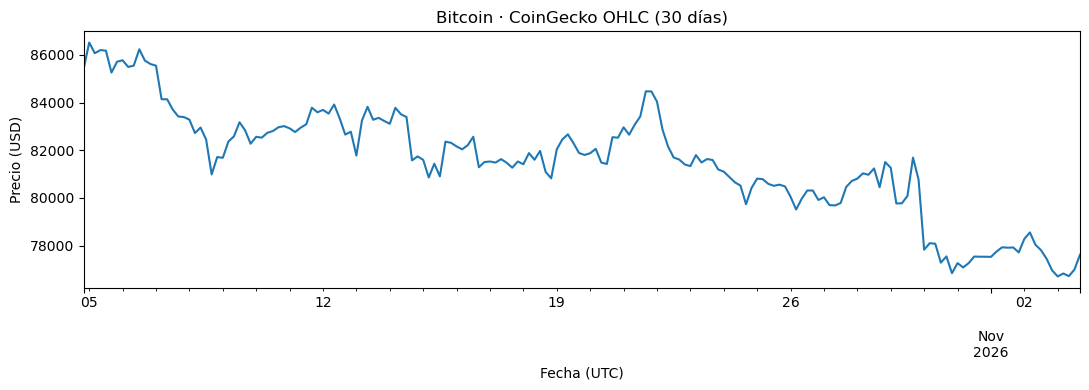

✓ Todas las comprobaciones finalizadas correctamente.


In [7]:
import matplotlib.pyplot as plt
ax = prices_df["close"].plot(figsize=(11, 4), title=f"{crypto.name} · CoinGecko OHLC ({DAYS} días)")
ax.set_xlabel("Fecha (UTC)")
ax.set_ylabel(f"Precio ({CURRENCY.upper()})")
plt.tight_layout()
plt.show()
print("✓ Todas las comprobaciones finalizadas correctamente.")

### Problemas habituales

- **`ModuleNotFoundError`**: comprueba que `src/models/` contiene los módulos y que el kernel está trabajando desde `tests/` o desde la raíz del repositorio.
- **No se encuentra la raíz**: abre `Financial-Toolkit` como proyecto y ejecuta el notebook desde ahí; debe existir `pyproject.toml`.
- **API Key ausente**: guarda `COINGECKO_API_KEY=...` en el `.env` de la **raíz**, no en `tests/`. Verifica que `.env` está en `.gitignore`.
- **401/403/429**: revisa la clave, el plan y los límites de CoinGecko Demo.
- **Error en `Tokenomics`**: asegúrate de que `coingecko_api.py` contiene `from tokenomics import Tokenomics`.
- **Error de volumen**: el endpoint OHLC no incluye volumen; usa `volume=None`.
